# Solar PV Panel Defect Detection Using Multimodal Fusion Architecture

## Module-1: Defining the Problem Statement

* Photovoltaic (PV) solar panels are susceptible to various kind of wear and tear such as: Thermal Fatigue, Micro-Cracking during fabrication, transportation, installatiion. 
* These wear and tear directly results in performance degradation of the solar panels.
* To detect those degraded panels the PV panels are imaged using Electroluminescence (EL) imaging techniques and respectve electrical sensor readings are noted.
* The EL imaging is subjective to low radiometric contrast, sensor speckle noise, and visual artifacts, especially in polycrystalline silicon wafers the grain boundaries and micro cracks sometimes and look identical and hard to detect.
* Similarly the sensor reading alone is not sufficient enough to accurately detect the degraded panels as it may sometimes contains irregular reading and suffer form various noises such as sensor acquisition noise, thermal noise, etc.
* We are addressing this problem by using a multimodal fusion network to consider both the EL images and the sensor readings for classifying the PV cells according to their defect percentage.


## Module-2: Dataset Loading and Exploratory Data Analysis (EDA)

* Using the ELPV dataset

       filename  defect_prob wafer_type
0  cell0000.png          1.0       mono
1  cell0001.png          1.0       mono
2  cell0002.png          1.0       mono
3  cell0003.png          0.0       mono
4  cell0004.png          1.0       mono


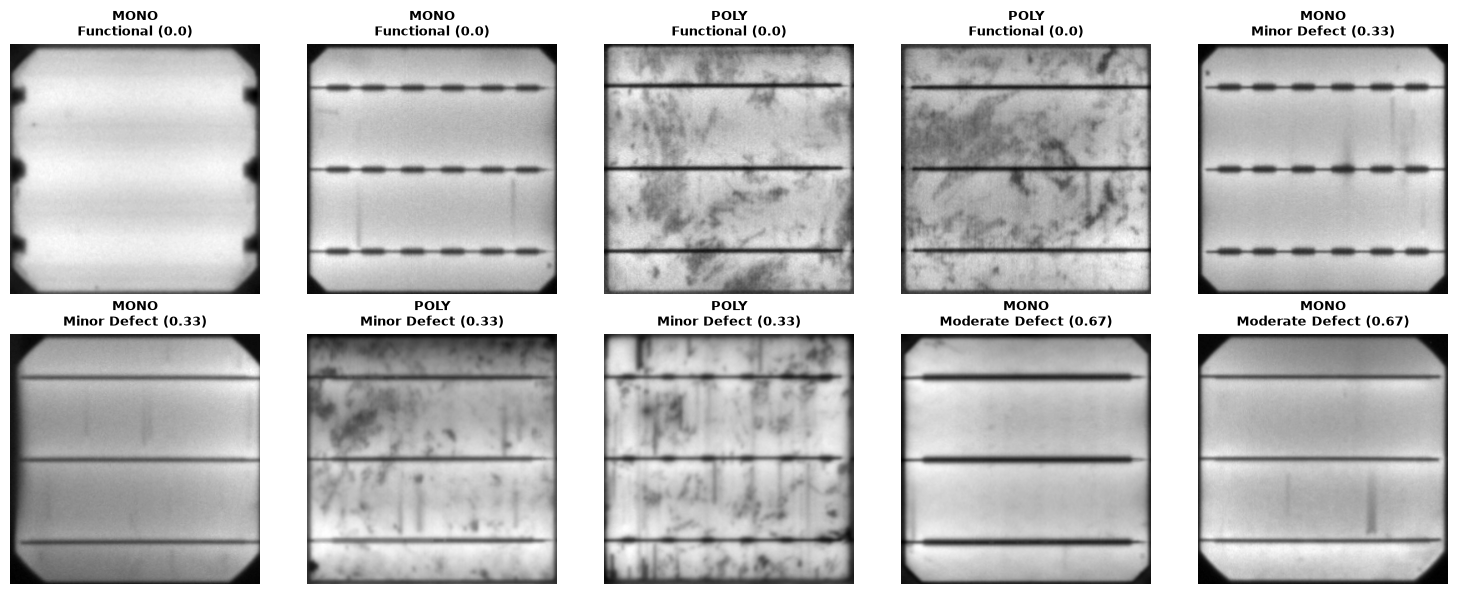

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
import copy

torch.set_num_threads(2)

SRC_DIR = Path(__file__).resolve().parent if "__file__" in locals() else Path.cwd()
PROJECT_ROOT = SRC_DIR.parent if SRC_DIR.name in ["src", "notebooks"] else SRC_DIR

LABELS_PATH = PROJECT_ROOT / "data" / "labels.csv"
IMAGES_DIR = PROJECT_ROOT / "data" / "raw" / "elpv_images"

pv_labels = pd.read_csv(LABELS_PATH)
print(pv_labels.head())

# Ensuring columns are stripped of accidental leading/trailing spaces
pv_labels.columns = pv_labels.columns.str.strip()

pv_labels["full_path"] = [IMAGES_DIR / str(fname).strip() for fname in pv_labels["filename"]]

# Stratified Sampling 
sampled_groups = []
for _, group in pv_labels.groupby(["defect_prob", "wafer_type"]):
    # Sample up to 2 items per group safely
    n_samples = min(len(group), 2)
    sampled_groups.append(group.sample(n=n_samples, random_state=42))

# Combining back into a single dataframe and taking the first 10 data
samples = pd.concat(sampled_groups).head(10).reset_index(drop=True)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

defect_descriptions = {
    0.0: "Functional (0.0)",
    0.333: "Minor Defect (0.33)",
    0.667: "Moderate Defect (0.67)",
    1.0: "Severe / Broken (1.0)"
}

for i, (_, row) in enumerate(samples.iterrows()):
    img_path: Path = row["full_path"]
    
    if img_path.is_file():
        with Image.open(img_path) as img:
            axes[i].imshow(img.convert("L"), cmap="gray")
    else:
        axes[i].text(0.5, 0.5, f"Missing:\n{img_path.name}", 
                     ha="center", va="center", color="red", fontsize=8)

    prob_val = float(row["defect_prob"])
    prob_key = round(prob_val, 3)
    
    label_desc = defect_descriptions.get(prob_key, f"Prob: {prob_val}")
    wafer_str = str(row['wafer_type']).strip().upper()
    
    axes[i].set_title(f"{wafer_str}\n{label_desc}", fontsize=9, fontweight="bold")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

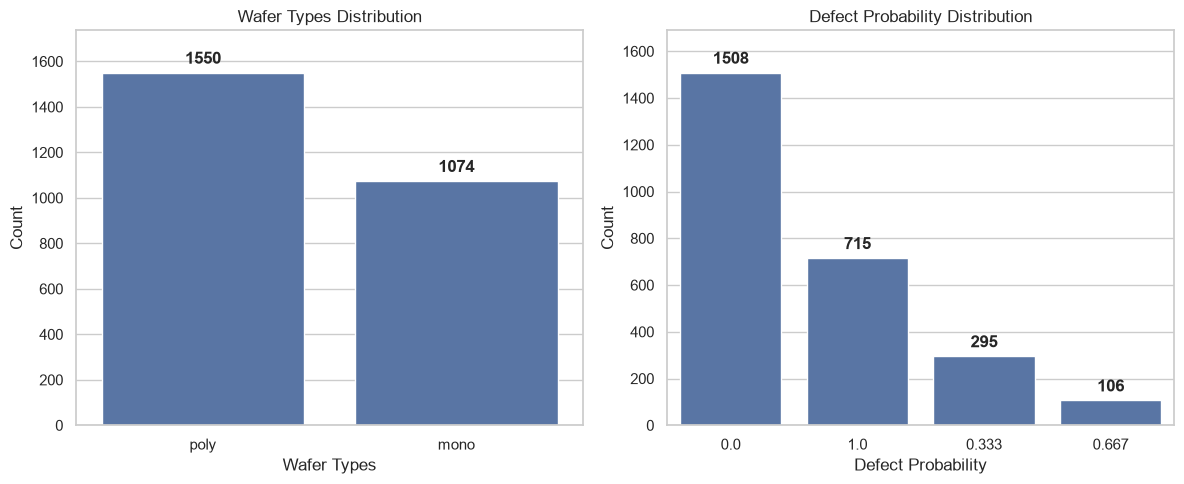

In [2]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12,5))

def plotDistributions(dataset,feature,title,i):
    plt.subplot(1,2,i)
    sns.countplot(data=dataset,
              x=feature,
              order=dataset[feature].value_counts().index)
    plt.title(f"{title} Distribution")
    plt.xlabel(title)
    plt.ylabel("Count")

    for c in plt.gca().containers:
        plt.gca().bar_label(c, padding=4, fontweight="bold")
    plt.margins(y=0.12)

plotDistributions(pv_labels,'wafer_type','Wafer Types',1)
plotDistributions(pv_labels,'defect_prob','Defect Probability',2)

plt.tight_layout()
plt.show()

* From the image we can infer that the dataset is skewed, the defect probability 0.333 and 0.667 are under represented in the dataset. 
* And defect probability 0.0 has more double samples than of the second most represented defect probability 1.0.
* To increase the variations and to make our model more robust to bias, we are generating a synthetic sensor readings from the available defect probability of the PV cells.

In [3]:
TELEMETRY_PATH = PROJECT_ROOT / "data" / "paired_telemetry.csv"
pv_telemetry = pd.read_csv(TELEMETRY_PATH)
pv_telemetry.head(10)

,filename,defect_prob,wafer_type,irradiance_w_m2,cell_temp_c,specific_power_w,specific_yield_kwh_kwp
0,cell0000.png,1.0,mono,840.8,63.10,4.766,3.093
1,cell0001.png,1.0,mono,801.4,65.45,4.361,3.189
2,cell0002.png,1.0,mono,828.4,60.21,4.623,2.410
3,cell0003.png,0.0,mono,708.4,49.92,5.624,3.674
4,cell0004.png,1.0,mono,960.1,67.40,5.071,2.840
5,cell0005.png,1.0,mono,680.8,64.70,3.695,2.287
6,cell0006.png,1.0,mono,893.5,66.14,4.696,2.437
7,cell0007.png,1.0,mono,742.3,61.80,4.176,3.000
8,cell0008.png,0.0,mono,778.2,46.08,6.263,2.526
9,cell0009.png,1.0,mono,892.6,65.08,4.788,2.232


In [4]:
pv_telemetry.groupby('defect_prob').describe().T.round(2)

defect_prob                     0.000   0.333   0.667   1.000
irradiance_w_m2        count  1508.00  295.00  106.00  715.00
                       mean    781.98  779.17  790.55  782.04
                       std     103.11  104.25   98.43   99.67
                       min     471.40  492.70  588.60  483.00
                       25%     708.88  703.70  726.30  714.55
                       50%     787.35  777.00  787.55  786.80
                       75%     862.32  864.30  864.85  856.45
                       max     998.00  992.00  983.40  992.70
cell_temp_c            count  1508.00  295.00  106.00  715.00
                       mean     48.92   52.06   57.43   63.24
                       std       4.88    4.81    4.14    4.58
                       min      33.58   37.56   48.99   46.29
                       25%      45.43   48.78   54.40   60.33
                       50%      49.04   51.81   57.48   63.48
                       75%      52.23   55.40   60.64   66.18
                       max      62.47   64.34   67.70   76.09
specific_power_w       count  1508.00  295.00  106.00  715.00
                       mean      5.92    5.52    5.01    4.13
                       std       0.74    0.68    0.61    0.49
                       min       3.37    3.75    3.64    2.62
                       25%       5.43    4.98    4.57    3.77
                       50%       5.96    5.51    5.00    4.16
                       75%       6.46    6.01    5.48    4.49
                       max       7.71    7.16    6.33    5.47
specific_yield_kwh_kwp count  1508.00  295.00  106.00  715.00
                       mean      3.43    3.32    3.02    2.53
                       std       0.91    0.87    0.81    0.68
                       min       0.99    1.30    1.28    0.73
                       25%       2.81    2.73    2.37    2.06
                       50%       3.44    3.24    2.95    2.51
                       75%       4.04    3.90    3.62    3.00
                       max       6.06    5.66    5.01    4.47

In [5]:
pv_telemetry.info()

<class 'pandas.DataFrame'>
RangeIndex: 2624 entries, 0 to 2623
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   filename                2624 non-null   str    
 1   defect_prob             2624 non-null   float64
 2   wafer_type              2624 non-null   str    
 3   irradiance_w_m2         2624 non-null   float64
 4   cell_temp_c             2624 non-null   float64
 5   specific_power_w        2624 non-null   float64
 6   specific_yield_kwh_kwp  2624 non-null   float64
dtypes: float64(5), str(2)
memory usage: 143.6 KB


* Extracting telemetry feature names. Since the Shunt Resistance is exponentially related across the degredation of wafers, using log transform of it.

In [6]:
telemetry_features = ["irradiance_w_m2", "cell_temp_c", "specific_power_w", 
"specific_yield_kwh_kwp"]

* Plotting a Corrrelation matrix (heatmap) to spot any *multicolliearity* between the features of the telemetry dataset. 

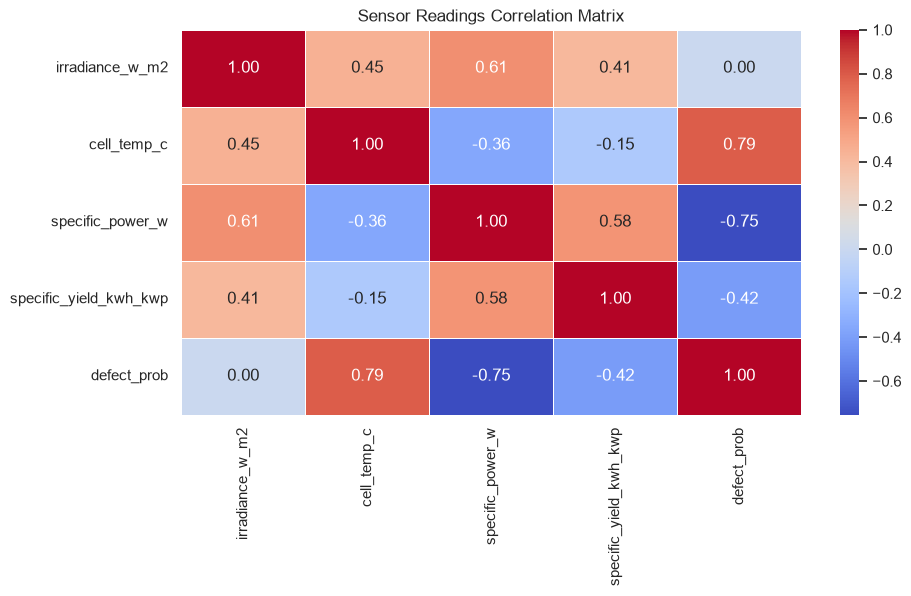

In [7]:
plt.figure(figsize=(10, 5))
corr_matrix=pv_telemetry[telemetry_features + ['defect_prob']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Sensor Readings Correlation Matrix")
plt.show()

* Plotting Violin plots to visualise the probability density of each features across different defect labels.

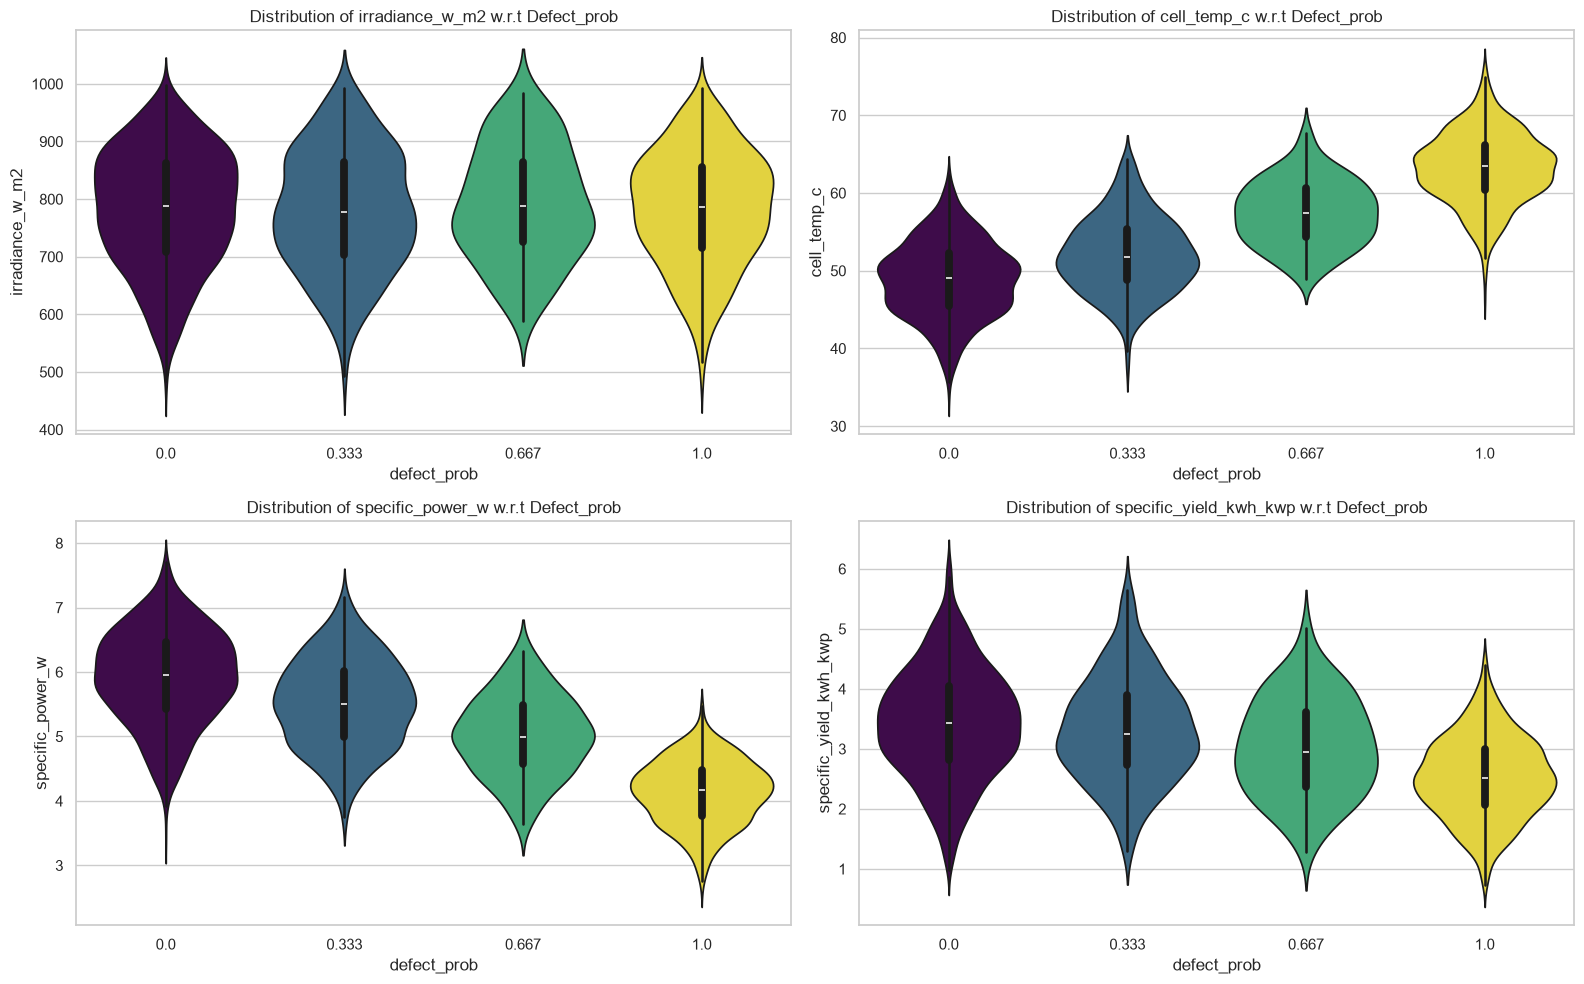

In [8]:
def plot_violins(df, features_list, target):
    # Determine the number of rows needed for subplots
    n_features = len(features_list)
    rows = (n_features + 1) // 2
    
    plt.figure(figsize=(16, 5 * rows))
    
    for i, col in enumerate(features_list):
        plt.subplot(rows, 2, i + 1)
        # We plot the feature against the Quality categories
        sns.violinplot(x=target, y=col, data=df, hue=target, palette="viridis", legend=False)
        plt.title(f"Distribution of {col} w.r.t {target.capitalize()}")
        
    plt.tight_layout()
    plt.show()

plot_violins(pv_telemetry,telemetry_features,'defect_prob')

<Figure size 1200x700 with 0 Axes>

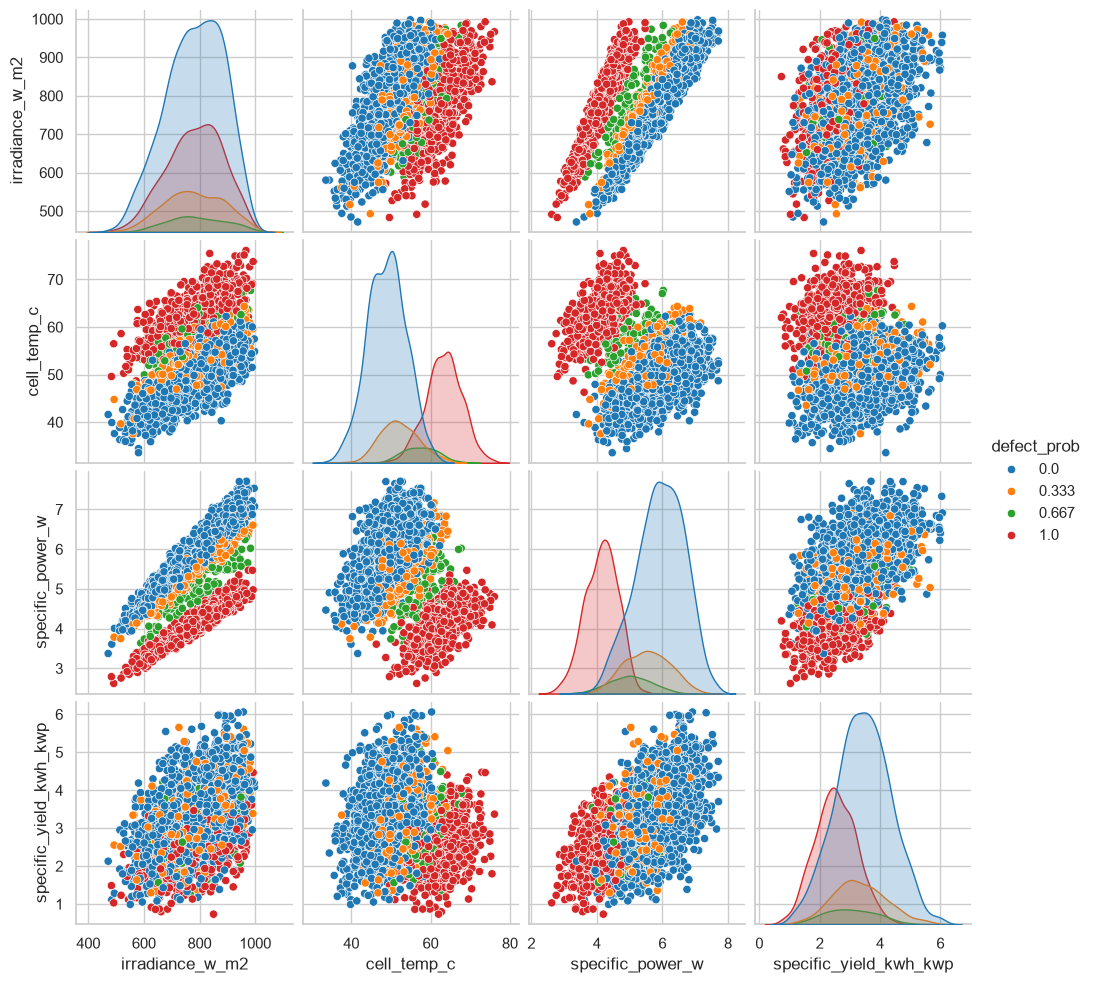

In [9]:
plt.figure(figsize=(12,7))
sns.pairplot(pv_telemetry[telemetry_features + ["defect_prob"]], hue="defect_prob", diag_kind="kde", palette="tab10")
plt.show()

* We can clearly see the interation of the sensor readings of each different features in the pairplot (scatterplot matrix).
* It provided univariate relationship of each feature as KDE plot in the diagonals and bivariate relatonship between each features pairwise as scatterplot elsewhere.
* We can clearly see the boundary amabiguity between defect probability class 0.333 and 0.667 in the scatterplots, while the 0.0 and 1.0 defect probability class cell points separates clearly relative to others.
* This will directly result in poor performance if only the sensor readings are considered for the prediction, hence requiring to be paired with the respective Electroluminescence image for making accurate predictions.

# Module-3: Data Preprocessing & Train-Test Split

* We are also performing data augmentation to increase the size of the training dataset before feeding to the model.
* We are performing all 8 types of augmentation in $D_4$ (the dihedral group of order 8).
$$\text{Group } D_4 = \{I, R_{90}, R_{180}, R_{270}, F_H, F_V, F_H \circ R_{90}, F_V \circ R_{90}\}$$
* The expected increase in dataset when performing $D_4$ augmentation is given below:

| Defect Class | Severity Meaning | Total in ELPV | Train Split (80%) | After $D_4$ Augmentation |
| --- | --- | --- | --- | --- |
| **0.0** | Functional Wafer | 1,508 (57.5%) | ~1,206 | 9,648 |
| **0.33** | Minor Defect | 295 (11.2%) | ~236 | 1,888 |
| **0.67** | Moderate Defect | 106 (4.0%) | ~85 | 680 |
| **1.0** | Severe Defect / Broken Wafer | 715 (27.3%) | ~572 | 4,576 |


In [10]:
CLASS_MAP = {0.0: 0, 0.333: 1, 0.667: 2, 1.0: 3}
pv_telemetry["image_path"] = pv_telemetry["filename"].apply(lambda fn: str(IMAGES_DIR / Path(fn).name))

# Quick sanity check on the first image path
assert Path(pv_telemetry["image_path"].iloc[0]).exists(), (f"Could not find image at: {pv_telemetry['image_path'].iloc[0]}")


def apply_exact_dihedral_batch(imgs: torch.Tensor, transform_ids: torch.Tensor) -> torch.Tensor:
  out = torch.empty_like(imgs)

  for tid in range(8):
    mask = transform_ids == tid
    if not mask.any():
      continue

    sub = imgs[mask]
    if tid == 0:
      out[mask] = sub # Identity
    elif tid == 1:
      out[mask] = torch.rot90(sub, 1, dims=[2, 3]) # 90°
    elif tid == 2:
      out[mask] = torch.rot90(sub, 2, dims=[2, 3]) # 180°
    elif tid == 3:
      out[mask] = torch.rot90(sub, 3, dims=[2, 3]) # 270°
    elif tid == 4:
      out[mask] = torch.flip(sub, dims=[3]) # Horizontal flip
    elif tid == 5:
      out[mask] = torch.flip(sub, dims=[2]) # Vertical flip
    elif tid == 6:
      out[mask] = torch.rot90(torch.flip(sub, dims=[3]), 1, dims=[2, 3]) # Diagonal 1
    elif tid == 7:
      out[mask] = torch.rot90(torch.flip(sub, dims=[2]), 1, dims=[2, 3]) # Diagonal 2

  return out

In [11]:
class MultimodalPVDataset(Dataset):
    def __init__(self, df: pd.DataFrame, scaler, is_train: bool, expand_8x: bool):
        self.df = df.reset_index(drop=True)
        self.is_train = is_train
        self.expand_8x = expand_8x if is_train else False
        
        # Pre-converting tabular data to torch tensors in RAM
        raw_tabular = self.df[telemetry_features].values.astype(np.float32)
        self.scaled_tabular = torch.from_numpy(scaler.transform(raw_tabular).astype(np.float32))
        
        self.image_paths = self.df["image_path"].values
        self.labels = torch.tensor(self.df["defect_prob"].round(3).map(CLASS_MAP).values, dtype=torch.long)
        self.to_tensor = transforms.ToTensor()
        
        # Pre-loading all images directly into RAM as (1, 300, 300) tensors
        self.cached_images = [self.to_tensor(Image.open(p).convert("L")) for p in self.image_paths]

    def __len__(self):
        # 1,679 * 8 = 13,432 for train; 420 for val
        return len(self.df) * 8 if self.expand_8x else len(self.df)

    def __getitem__(self, idx):
        if self.expand_8x:
            base_idx = idx // 8
            transform_id = idx % 8
        else:
            base_idx = idx
            transform_id = 0

        return (
            self.cached_images[base_idx],
            self.scaled_tabular[base_idx],
            transform_id,
            self.labels[base_idx]
        )

In [12]:
def prepare_splits(df: pd.DataFrame):
    # Composite key ensures both defect_prob and wafer_type (mono/poly) are balanced
    strat_key = df["defect_prob"].astype(str) + "_" + df["wafer_type"].str.lower().str.strip()

    # 80% Train, 20% Test
    train_df, test_df = train_test_split(df,test_size=0.20,random_state=42,stratify=strat_key,shuffle=True)

    train_df = train_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # Assigning 5 Stratified Folds inside the train_df
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    train_strat_key = train_df["defect_prob"].astype(str) + "_" + train_df["wafer_type"].str.lower().str.strip()

    train_df["fold"] = -1
    for fold_idx, (_, val_idx) in enumerate(skf.split(train_df, train_strat_key)):
        train_df.loc[val_idx, "fold"] = fold_idx

    return train_df, test_df

In [13]:
def get_fold_dataloaders(train_df: pd.DataFrame, val_fold: int, batch_size: int):
    fold_train_df = train_df[train_df["fold"] != val_fold].reset_index(drop=True)
    fold_val_df   = train_df[train_df["fold"] == val_fold].reset_index(drop=True)

    # Fitting StandardScaler on the 4 training folds
    scaler = StandardScaler()
    scaler.fit(fold_train_df[telemetry_features].values.astype(np.float32))

    train_dataset = MultimodalPVDataset(fold_train_df, scaler, True, True)
    val_dataset = MultimodalPVDataset(fold_val_df, scaler, False, False)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
    val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

    return train_loader, val_loader, scaler


def get_test_dataloader(train_df: pd.DataFrame, test_df: pd.DataFrame, batch_size: int):
    # Fit StandardScaler on the entire 80% training pool before transforming the 20% test set
    full_train_scaler = StandardScaler()
    full_train_scaler.fit(train_df[telemetry_features].values.astype(np.float32))

    test_dataset = MultimodalPVDataset(test_df,full_train_scaler,False,False)

    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)
    return test_loader, full_train_scaler

In [14]:
train_df, test_df = prepare_splits(pv_telemetry)

print("\nk-Fold Class Distribution inside Train Set:")
print(pd.crosstab(train_df["fold"], train_df["defect_prob"]))

train_loader, val_loader, fold0_scaler = get_fold_dataloaders(train_df, val_fold=0, batch_size=32)
test_loader, full_scaler = get_test_dataloader(train_df, test_df, batch_size=32)

print(f"\nFold 0 Train Dataset Length: {len(train_loader.dataset)} ({len(train_loader)} batches)")
print(f"Fold 0 Val Dataset Length: {len(val_loader.dataset)} ({len(val_loader)} batches)")
print(f"Test Dataset Length: {len(test_loader.dataset)} ({len(test_loader)} batches)")

# Verifying one batch from TrainLoader
img_batch, sensor_batch, transform_id_batch, label_batch = next(iter(train_loader))
print(
    f"\nBatch Shapes -> Images: {img_batch.shape}, "
    f"Sensors: {sensor_batch.shape}, "
    f"Transform IDs: {transform_id_batch.shape}, "
    f"Labels: {label_batch.shape}")


k-Fold Class Distribution inside Train Set:
defect_prob  0.000  0.333  0.667  1.000
fold                                   
0              241     47     17    115
1              241     47     17    115
2              242     47     17    114
3              241     48     17    114
4              241     47     17    114

Fold 0 Train Dataset Length: 13432 (420 batches)
Fold 0 Val Dataset Length: 420 (14 batches)
Test Dataset Length: 525 (17 batches)

Batch Shapes -> Images: torch.Size([32, 1, 300, 300]), Sensors: torch.Size([32, 4]), Transform IDs: torch.Size([32]), Labels: torch.Size([32])


# Module-4: MultiModal Fusion Architecture Implementation

* For the MLP Branch, using 4 --> 32 --> 16 architecture, where we have four features as input and two hidden layers one with 32 neurons and another with 16 neurons respectively.
* For the CNN branch, using a 4-stage CNN architecture as described in below figure.
* During late-fusion, concatinating the CNN branch output and MLP branch output and passing it to layers as described in below figure.

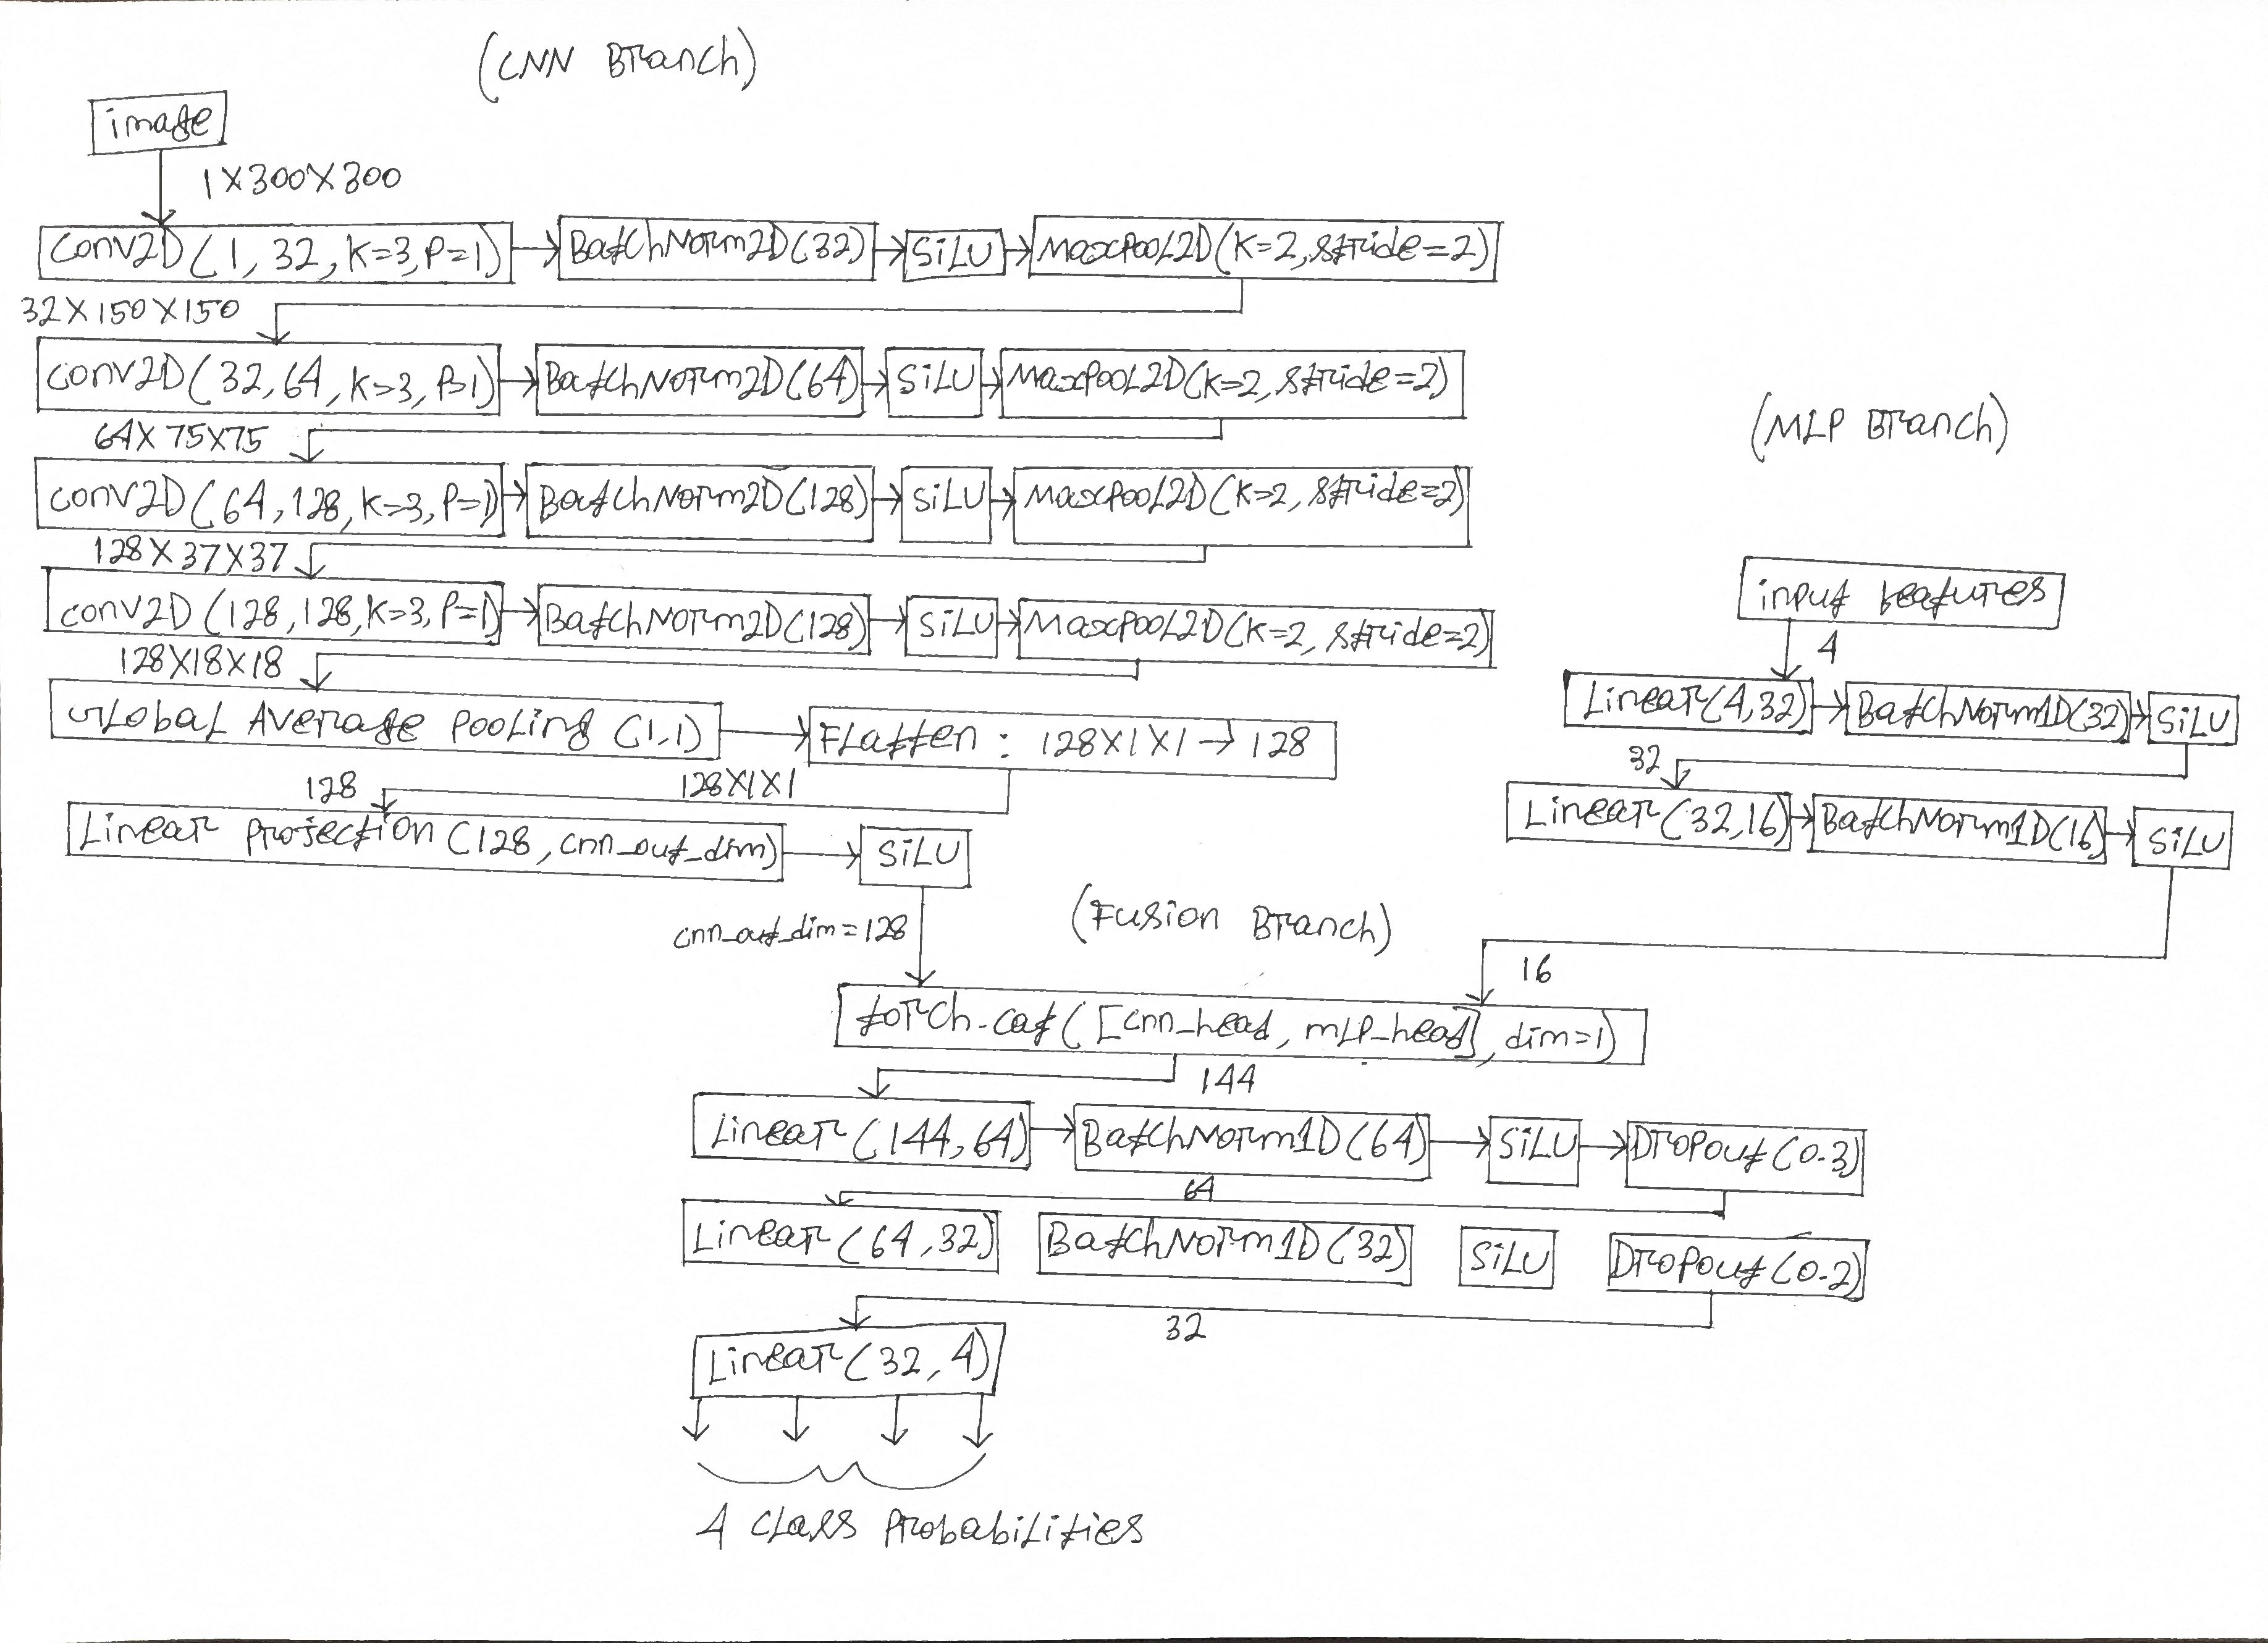

* To prevent the CNN branch (which has dimension (128,18,18) after the 4-th Conv2D layer) from supressing the representation of MLP branch (which have dimension (16) after 2-nd hidden layer), using Global Average Pooling (GAP) on the CNN output and including Batch Normalization, Dropout in the Fusion network.
* Using SiLU (Sigmoid Linear Unit) as our activation function. 
$$\text{SiLU}(x) = x \cdot \sigma(x) = \frac{x}{1 + e^{-x}}$$

In [15]:
# CNN Head (4-Stage ConvNet)
class CNNBranch(nn.Module):
    def __init__(self, visual_out_dim: int):
        super().__init__()
        self.features = nn.Sequential(
            # Stage 1: 1x300x300 -> 32x150x150
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Stage 2: 32x150x150 -> 64x75x75
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.SiLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Stage 3: 64x75x75 -> 128x37x37
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.SiLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Stage 4: 128x37x37 -> 128x18x18
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.SiLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        
        # Global Average pooling
        self.gap = nn.AdaptiveAvgPool2d((1, 1)) # 128x18x18 -> 128x1x1
        self.projection = nn.Linear(128, visual_out_dim)
        self.act = nn.SiLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        return self.act(self.projection(x))

# MLP Head (2 hidden layers)
class TabularMLP(nn.Module):
    def __init__(self, in_features: int, tabular_out_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 32),
            nn.BatchNorm1d(32),
            nn.SiLU(inplace=True),
            
            nn.Linear(32, tabular_out_dim),
            nn.BatchNorm1d(tabular_out_dim),
            nn.SiLU(inplace=True)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

# Multimodal Late-Fusion PV Classifier (2 hidden layers)
class MultimodalLateFusionPV(nn.Module):
    def __init__(self, num_classes: int, visual_dim: int, tabular_dim: int):
        super().__init__()
        self.cnn_head = CNNBranch(visual_out_dim=visual_dim)
        self.mlp_head = TabularMLP(in_features=4, tabular_out_dim=tabular_dim)
        
        fused_dim = visual_dim + tabular_dim # 144

        self.fusion_head = nn.Sequential(
            nn.Linear(fused_dim, 64),
            nn.BatchNorm1d(64),
            nn.SiLU(inplace=True),
            nn.Dropout(p=0.3),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.SiLU(inplace=True),
            nn.Dropout(p=0.2),

            nn.Linear(32, num_classes)
        )

    def forward(self, img: torch.Tensor, sensor: torch.Tensor) -> torch.Tensor:
        # Extracting respective features
        v_feat = self.cnn_head(img) # Shape: (B, 128)
        t_feat = self.mlp_head(sensor) # Shape: (B, 16)

        # Concatenating along channel dimension
        fused = torch.cat([v_feat, t_feat], dim=1) # Shape: (B, 144)

        # Classification
        return self.fusion_head(fused) # Shape: (B, 4)

# Module-5: Model Training and Evaluation

* To address the class imbalance in our dataset distribution we have seen during EDA, we are using Focal Loss instead of Cross-Entropy.
### Mathematical Formulation of Focal Loss:
* Focal Loss adds a non-linear modulating factor $(1 - p_t)^\gamma$ to the Cross-Entropy loss, parameterized by a tunable focusing parameter $\gamma \ge 0$:
$$\text{FL}(p_t) = -(1 - p_t)^\gamma \log(p_t)$$

* Incorporating the class-balancing parameter $\alpha_t$ produces the complete $\alpha$-balanced Focal Loss:

$$\text{FL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$

#### Properties of the Modulating Factor $(1 - p_t)^\gamma$:

1. **Misclassified / Hard Examples ($p_t \to 0$):**
* The factor $(1 - p_t) \to 1$.
* As a result, $(1 - p_t)^\gamma \approx 1$, and the loss behaves almost identically to standard Cross-Entropy:

$$\lim_{p_t \to 0} \text{FL}(p_t) = \text{CE}(p_t)$$

2. **Well-Classified / Easy Examples ($p_t \to 1$):**
* The factor $(1 - p_t) \to 0$.
* As $p_t$ approaches $1$, $(1 - p_t)^\gamma$ collapses to zero exponentially fast, suppressing the loss contribution:

$$\lim_{p_t \to 1} \text{FL}(p_t) = 0 \cdot (-\log(1)) = 0$$

3. **The Role of $\gamma$:**
* When $\gamma = 0$, Focal Loss is mathematically equivalent to standard Cross-Entropy ($\text{FL} \equiv \text{CE}$).
* As $\gamma$ increases, the contribution of easy examples to Loss decreases.

#### For Multi-class:
* For classification tasks with $C > 2$ mutually exclusive classes, predictions are computed using the **Softmax** activation:

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^C e^{z_j}}, \quad k \in \{1, \dots, C\}$$

Given one-hot ground-truth targets $\mathbf{y} \in \{0, 1\}^C$ where $y_c = 1$ for the true class $c$:

$$\text{FL}(\mathbf{p}, \mathbf{y}) = -\sum_{c=1}^C \alpha_c \, y_c \, (1 - p_c)^\gamma \log(p_c)$$

Since $y_c = 0$ for all non-target classes, the loss reduces to the target class probability $p_t$:

$$\text{FL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$

Where:

* $p_t = \sum_{c=1}^C y_c p_c$ is the predicted probability for the correct ground-truth class.
* $\alpha_t \in \mathbb{R}^C$ is an optional class-frequency weight vector ($w_c = \frac{1}{N_c}$), or $\alpha_t = \left(\frac{N_{\text{total}}}{N_t}\right)^{0.5}$


In [16]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing pipeline on device: {device}")


# Multi-Class Focal Loss
class MultiClassFocalLoss(nn.Module):
    def __init__(self, gamma: float = 2.0, alpha: torch.Tensor = None, reduction: str = "mean"):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.reduction = reduction

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # logits: (B, C), targets: (B,)
        log_p = F.log_softmax(logits, dim=-1)
        p = torch.exp(log_p)

        # Gathering true class probabilities
        target_log_p = log_p.gather(dim=-1, index=targets.unsqueeze(-1)).squeeze(-1)
        target_p = p.gather(dim=-1, index=targets.unsqueeze(-1)).squeeze(-1)

        focal_term = (1.0 - target_p) ** self.gamma
        loss = -focal_term * target_log_p

        if self.alpha is not None:
            alpha_t = self.alpha.to(logits.device).gather(dim=0, index=targets)
            loss = alpha_t * loss

        if self.reduction == "mean":
            return loss.mean()
        elif self.reduction == "sum":
            return loss.sum()
        return loss

Executing pipeline on device: cuda


In [23]:
# Confusion matrix
def makeConfusionMatrix(cm):
    plt.figure(figsize=(12,7))
    sns.heatmap(cm, annot=True, cmap='Blues', fmt="d", linewidths=0.5)
    plt.xlabel("Predicted Label", fontsize=11, fontweight="bold")
    plt.ylabel("Actual Label", fontsize=11, fontweight="bold")
    plt.title("Classification Confusion Matrix")
    plt.show() 

In [18]:
# Training & Validation Functions
def train_one_epoch(model, loader, optimizer, criterion, device, max_grad_norm=1.0):
    model.train()
    running_loss_tensor = 0.0
    jitter_std=0.05
    all_preds, all_targets = [], []
    scaler_amp = torch.amp.GradScaler('cuda')

    for imgs, sensors, transform_ids, labels in loader:
        # Asynchronous transfer to GPU VRAM
        imgs = imgs.to(device, non_blocking=True)
        sensors = sensors.to(device, non_blocking=True)
        transform_ids = transform_ids.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # GPU-Aided Data Augmentation
        imgs = apply_exact_dihedral_batch(imgs, transform_ids)
        
        # GPU-Aided Vectorized Sensor Jitter
        if jitter_std > 0.0:
            sensors = sensors + torch.randn_like(sensors) * jitter_std

        optimizer.zero_grad(set_to_none=True)

        # Forward pass through CNN + MLP + Fusion Head
        with torch.amp.autocast('cuda'):
            logits = model(imgs, sensors)
            loss = criterion(logits, labels)

        # Backpropagation
        scaler_amp.scale(loss).backward()
        scaler_amp.unscale_(optimizer)

        # Gradient clipping to prevent gradient explosion through late-fusion layers
        if max_grad_norm > 0.0:
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)

        scaler_amp.step(optimizer)
        scaler_amp.update()

        running_loss_tensor += loss.detach() * labels.size(0)
        all_preds.append(torch.argmax(logits.detach(), dim=1))
        all_targets.append(labels)
        # running_loss += loss.item() * labels.size(0)
        # preds = torch.argmax(logits, dim=1)
        # all_preds.extend(preds.cpu().numpy())
        # all_targets.extend(labels.cpu().numpy())

    # epoch_loss = running_loss_tensor / len(loader.dataset)
    epoch_loss = (running_loss_tensor / len(loader.dataset)).item()
    all_preds_cpu = torch.cat(all_preds).cpu().numpy()
    all_targets_cpu = torch.cat(all_targets).cpu().numpy()
    epoch_macro_f1 = f1_score(all_targets_cpu, all_preds_cpu, average="macro", zero_division=0)
    
    return epoch_loss, epoch_macro_f1

In [19]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_targets = [], []

    for imgs, sensors, _, labels in loader:
        imgs = imgs.to(device, non_blocking=True)
        sensors = sensors.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast('cuda'):
            logits = model(imgs, sensors)
            loss = criterion(logits, labels)

        running_loss += loss.item() * labels.size(0)
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

    val_loss = running_loss / len(loader.dataset)
    val_macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return val_loss, val_macro_f1, np.array(all_preds), np.array(all_targets)


# k-Fold Cross-Validation
def run_stratified_kfold_cv(
    train_df: pd.DataFrame,
    num_folds: int = 5,
    epochs: int = 10,
    batch_size: int = 32,
    lr: float = 1e-3,
    weight_decay: float = 1e-2,
    gamma: float = 2.0,
    checkpoints_dir: Path = Path("./checkpoints")
):
    checkpoints_dir.mkdir(parents=True, exist_ok=True)
    cv_fold_models = []
    cv_metrics = []

    # Out-of-fold predictions storage for overall CV evaluation
    oof_predictions = np.zeros(len(train_df), dtype=np.int64)
    oof_ground_truth = np.zeros(len(train_df), dtype=np.int64)

    for fold in range(num_folds):
        print(f"\n{'-'*30} FOLD {fold} / {num_folds - 1} {'-'*30}")
        
        train_loader, val_loader, fold_scaler = get_fold_dataloaders(
            train_df=train_df,
            val_fold=fold,
            batch_size=batch_size
        )

        # Instantiaton of fresh model per fold
        model = MultimodalLateFusionPV(num_classes=4, visual_dim=128, tabular_dim=16).to(device)

        # AdamW optimizer
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay,
            betas=(0.9, 0.999),
            eps=1e-8
        )

        # Cosine Annealing learning rate schedule
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, 
            T_max=epochs, 
            eta_min=1e-6
        )
        
        # Square-root inverse class weighting for alpha
        class_counts = train_df["defect_prob"].round(3).map(CLASS_MAP).value_counts().sort_index().values
        alpha = torch.tensor((len(train_df) / class_counts) ** 0.5, dtype=torch.float32)
        alpha = alpha / alpha.sum() # Normalization of aplha value

        # Multi-Class Focal Loss calling
        criterion = MultiClassFocalLoss(gamma, alpha, reduction="mean")

        best_val_macro_f1 = -1.0
        best_model_weights = None
        best_val_preds = None
        best_val_targets = None

        for epoch in range(1, epochs + 1):
            train_loss, train_f1 = train_one_epoch(model, train_loader, optimizer, criterion, device)
            val_loss, val_f1, val_preds, val_targets = evaluate(model, val_loader, criterion, device)
            scheduler.step()

            # Saving best checkpoint tracking Macro F1
            if val_f1 > best_val_macro_f1:
                best_val_macro_f1 = val_f1
                best_model_weights = copy.deepcopy(model.state_dict())
                best_val_preds = val_preds
                best_val_targets = val_targets

            if epoch % 5 == 0 or epoch == epochs:
                print(
                    f"Epoch [{epoch:02d}/{epochs:02d}] | "
                    f"Train Loss: {train_loss:.4f} - Train F1: {train_f1:.4f} | "
                    f"Val Loss: {val_loss:.4f} - Val F1: {val_f1:.4f} | "
                    f"Best Val F1: {best_val_macro_f1:.4f}"
                )

        # Saving fold checkpoint to disk
        fold_ckpt_path = checkpoints_dir / f"multimodal_pv_fold_{fold}.pt"
        torch.save(
            {
                "fold": fold,
                "model_state_dict": best_model_weights,
                "scaler": fold_scaler,
                "best_macro_f1": best_val_macro_f1
            },
            fold_ckpt_path
        )
        print(f"Saved Fold {fold} Best Model -> {fold_ckpt_path}")

        # Storing OOF predictions
        val_indices = train_df[train_df["fold"] == fold].index.values
        oof_predictions[val_indices] = best_val_preds
        oof_ground_truth[val_indices] = best_val_targets

        cv_metrics.append(best_val_macro_f1)

        # Loading best weights for model artifact retention
        model.load_state_dict(best_model_weights)
        cv_fold_models.append(model)

    # Cross-Validation Performance Report Aggregation
    print(f"\n{'-'*25} K-FOLD CV FINAL SUMMARY {'-'*25}")
    for f_idx, score in enumerate(cv_metrics):
        print(f"Fold {f_idx} Best Validation Macro F1: {score * 100:.2f}%")
    
    mean_f1 = np.mean(cv_metrics)
    std_f1 = np.std(cv_metrics)
    print(f"\nMean CV Macro F1: {mean_f1 * 100:.2f}% (± {std_f1 * 100:.2f}%)")

    class_names = ["Defect 0.0", "Defect 0.333", "Defect 0.667", "Defect 1.0"]
    print("\nOverall Out-Of-Fold (OOF) Classification Report:")
    print(classification_report(oof_ground_truth, oof_predictions, target_names=class_names, digits=4))

    return cv_fold_models, cv_metrics

In [20]:
# Test Set Evaluation (Ensemble Inference)
@torch.no_grad()
def evaluate_holdout_test(models, test_loader, device):
    for m in models:
        m.eval()

    all_test_targets = []
    accumulated_probs = []

    for imgs, sensors, _, labels in test_loader:
        imgs = imgs.to(device, non_blocking=True)
        sensors = sensors.to(device, non_blocking=True)

        batch_probs = torch.zeros((labels.size(0), 4), device=device)

        # Softmax probability averaging across all 5 models
        for m in models:
            logits = m(imgs, sensors)
            batch_probs += F.softmax(logits, dim=-1)

        batch_probs /= len(models)
        accumulated_probs.append(batch_probs.cpu())
        all_test_targets.extend(labels.numpy())

    accumulated_probs = torch.cat(accumulated_probs, dim=0).numpy()
    final_preds = np.argmax(accumulated_probs, axis=1)
    all_test_targets = np.array(all_test_targets)

    test_macro_f1 = f1_score(all_test_targets, final_preds, average="macro", zero_division=0)
    test_acc = (final_preds == all_test_targets).mean()

    class_names = ["Defect 0.0", "Defect 0.333", "Defect 0.667", "Defect 1.0"]
    print(f"\n{'-'*25} HOLDOUT TEST EVALUATION (20%) {'-'*25}")
    print(f"Test Accuracy:  {test_acc * 100:.2f}%")
    print(f"Test Macro F1:  {test_macro_f1 * 100:.2f}%")
    print("\nHoldout Test Classification Report:")
    print(classification_report(all_test_targets, final_preds, target_names=class_names, digits=4))
    print("Confusion Matrix:")
    makeConfusionMatrix(confusion_matrix(all_test_targets, final_preds))

    return test_macro_f1, final_preds

In [21]:
# Running Stratified k-Fold Cross-Validation (10 Epochs per fold)
CHECKPOINTS_DIR = Path("./checkpoints")

cv_models, cv_scores = run_stratified_kfold_cv(
    train_df=train_df,
    num_folds=5,
    epochs=10,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-2,
    gamma=2.0,
    checkpoints_dir=CHECKPOINTS_DIR
)


------------------------------ FOLD 0 / 4 ------------------------------
Epoch [05/10] | Train Loss: 0.0116 - Train F1: 0.8693 | Val Loss: 0.0090 - Val F1: 0.9151 | Best Val F1: 0.9151
Epoch [10/10] | Train Loss: 0.0092 - Train F1: 0.8930 | Val Loss: 0.0076 - Val F1: 0.9315 | Best Val F1: 0.9315
Saved Fold 0 Best Model -> checkpoints\multimodal_pv_fold_0.pt

------------------------------ FOLD 1 / 4 ------------------------------
Epoch [05/10] | Train Loss: 0.0139 - Train F1: 0.8462 | Val Loss: 0.0114 - Val F1: 0.8784 | Best Val F1: 0.9180
Epoch [10/10] | Train Loss: 0.0096 - Train F1: 0.8860 | Val Loss: 0.0064 - Val F1: 0.9411 | Best Val F1: 0.9411
Saved Fold 1 Best Model -> checkpoints\multimodal_pv_fold_1.pt

------------------------------ FOLD 2 / 4 ------------------------------
Epoch [05/10] | Train Loss: 0.0110 - Train F1: 0.8696 | Val Loss: 0.0296 - Val F1: 0.6668 | Best Val F1: 0.9209
Epoch [10/10] | Train Loss: 0.0075 - Train F1: 0.9125 | Val Loss: 0.0054 - Val F1: 0.9577 | 


------------------------- HOLDOUT TEST EVALUATION (20%) -------------------------
Test Accuracy:  95.05%
Test Macro F1:  92.46%

Holdout Test Classification Report:
              precision    recall  f1-score   support

  Defect 0.0     0.9453    0.9735    0.9592       302
Defect 0.333     0.8235    0.7119    0.7636        59
Defect 0.667     1.0000    0.9524    0.9756        21
  Defect 1.0     1.0000    1.0000    1.0000       143

    accuracy                         0.9505       525
   macro avg     0.9422    0.9094    0.9246       525
weighted avg     0.9487    0.9505    0.9490       525

Confusion Matrix:


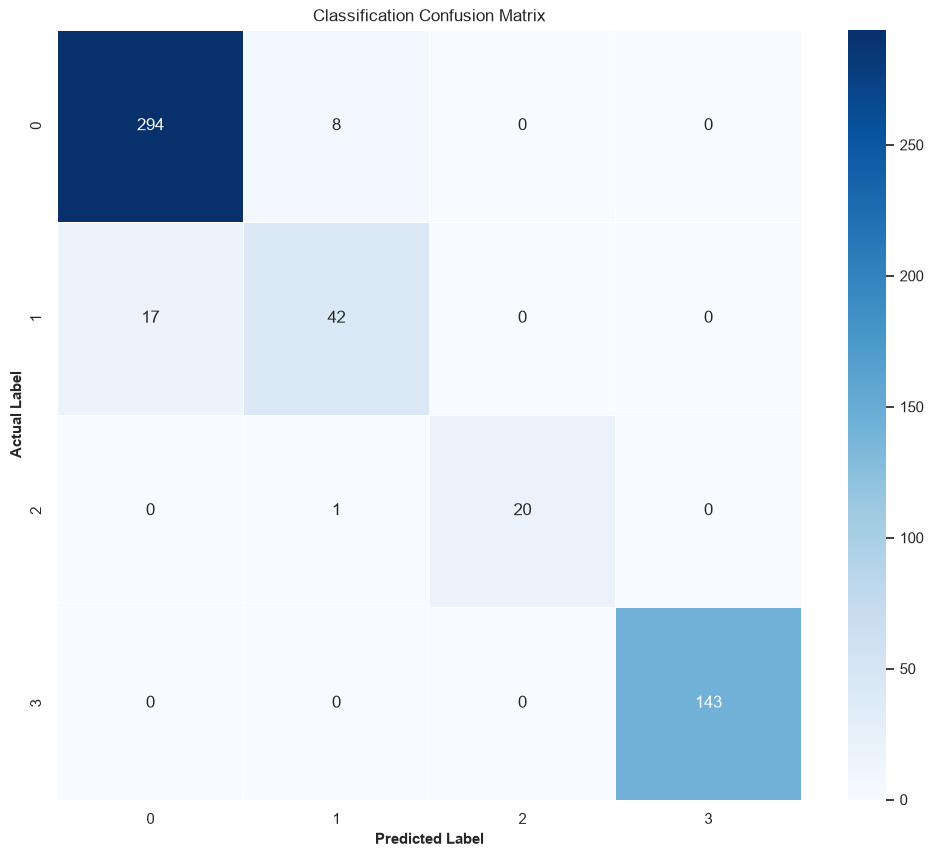

In [22]:
# Model Testing
test_macro_f1, test_predictions = evaluate_holdout_test(
    models=cv_models,
    test_loader=test_loader,
    device=device
)